<a href="https://colab.research.google.com/github/sanchitabirare07/cwi-knn-imputer/blob/main/notebooks/01_cwi_knn_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Missing Value Imputation — Our Custom Method vs Mean, Median & KNN
### SuperMarket Sales Dataset

**Goal of this notebook:** propose our own missing-value imputation method, and compare it against the three standard baselines — **Mean**, **Median**, and **KNN Imputation** — on a real dataset.

**What you'll find below:**
1. Load & inspect the dataset
2. Select the numeric columns we'll test on
3. Simulate missing values (since our dataset is complete, we remove some values ourselves so we know the "correct answer" and can measure accuracy)
4. Our own method — **Correlation-Weighted Iterative k-NN Imputation (CWI-kNN)** — explained in plain language
5. The three baseline methods
6. A fair comparison (same missing values, same evaluation metric, multiple missing-rates)
7. Result tables & charts
8. Conclusion, ready to present


## Step 0 — Setup

This cell installs and loads the libraries we need: pandas for handling tabular data, numpy for numerical operations, matplotlib/seaborn for plotting, and scikit-learn for the KNN baseline and evaluation metrics.

In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)
sns.set_style("whitegrid")
print("Libraries loaded.")

Libraries loaded.


## Step 1 — Load the dataset

We upload our raw dataset (SuperMarket_Analysis.csv) and load it into a pandas DataFrame. We check its shape and preview the first few rows to confirm it loaded correctly.

In [ ]:
FILE_NAME = "SuperMarket Analysis.csv"

df = pd.read_csv(FILE_NAME)
print("Shape:", df.shape)
df.head()

Shape: (1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


## Step 2 — Pick the columns to work with

Our method compares numeric columns to each other, so we select only the numeric columns (Unit price, Quantity, Tax 5%, Sales, cogs, gross income, Rating). We drop gross margin percentage because it's the same value in every row, so it has no relationship to anything else. We also print the correlation matrix — this shows how strongly each numeric column moves together with every other one, which is the foundation our own method is built on.

In [ ]:
numeric_cols = ['Unit price', 'Quantity', 'Tax 5%', 'Sales', 'cogs', 'gross income', 'Rating']
data = df[numeric_cols].copy()

print("Missing values currently in the dataset:")
print(data.isna().sum())

print("\nHow the numeric columns relate to each other (correlation):")
data.corr().round(2)

Missing values currently in the dataset:
Unit price      0
Quantity        0
Tax 5%          0
Sales           0
cogs            0
gross income    0
Rating          0
dtype: int64

How the numeric columns relate to each other (correlation):


,Unit price,Quantity,Tax 5%,Sales,cogs,gross income,Rating
Unit price,1.00,0.01,0.63,0.63,0.63,0.63,-0.01
Quantity,0.01,1.00,0.71,0.71,0.71,0.71,-0.02
Tax 5%,0.63,0.71,1.00,1.00,1.00,1.00,-0.04
Sales,0.63,0.71,1.00,1.00,1.00,1.00,-0.04
cogs,0.63,0.71,1.00,1.00,1.00,1.00,-0.04
gross income,0.63,0.71,1.00,1.00,1.00,1.00,-0.04
Rating,-0.01,-0.02,-0.04,-0.04,-0.04,-0.04,1.00


## Step 3 — Simulate missing values

Our dataset doesn't actually have any missing values, so to test how good an imputation method is, we have to create some ourselves. We randomly delete a percentage of values from each column (this is called MCAR — Missing Completely At Random) and remember exactly which cells we deleted and what their true values were. This lets us later check how close each method's guess was to the real answer.

In [ ]:
def introduce_missing(data, columns, rate, seed=0):
    """Randomly deletes `rate` fraction of values in each of `columns`.
    Returns the data-with-holes, and a boolean mask marking exactly which
    cells were removed (so we can check our answers later)."""
    rng = np.random.default_rng(seed)
    data_missing = data.copy()
    mask = pd.DataFrame(False, index=data.index, columns=data.columns)
    for col in columns:
        n = len(data)
        n_missing = int(n * rate)
        idx = rng.choice(n, size=n_missing, replace=False)
        mask.loc[data.index[idx], col] = True
        data_missing.loc[data.index[idx], col] = np.nan
    return data_missing, mask

# quick demo at 15% missing
data_missing_demo, mask_demo = introduce_missing(data, numeric_cols, rate=0.15, seed=1)
print("Missing values introduced:")
print(data_missing_demo.isna().sum())

Missing values introduced:
Unit price      150
Quantity        150
Tax 5%          150
Sales           150
cogs            150
gross income    150
Rating          150
dtype: int64


Step 4a — Values Intentionally Removed
Before we apply our method, let's look at exactly which values were hidden in Step 3. Each row below shows the original value from the dataset, and what that cell now looks like after removal (a blank / NaN). These are the values our method will never see — its job is to guess them back as closely as possible.

In [ ]:
col = 'Unit price'  # change this to inspect a different column

removed_values = pd.DataFrame({
    'Row Index': data.loc[mask_demo[col], col].index,
    'Original Value (now hidden)': data.loc[mask_demo[col], col].values,
    'Value in Dataset After Removal': data_missing_demo.loc[mask_demo[col], col].values,  # will show NaN
})

print(f"{mask_demo[col].sum()} values were intentionally removed from '{col}':")
removed_values.head(15)

150 values were intentionally removed from 'Unit price':


,Row Index,Original Value (now hidden),Value in Dataset After Removal
0,6,68.84,NaN
1,17,72.61,NaN
2,23,34.56,NaN
3,29,24.89,NaN
4,36,62.62,NaN
5,41,56.11,NaN
6,51,44.59,NaN
7,55,85.98,NaN
8,57,89.60,NaN
9,65,15.87,NaN


## Step 4b — Our Own Method: Correlation-Weighted Iterative k-NN Imputation (CWI-kNN)

### The idea, in plain words

Standard KNN imputation finds the "k most similar rows" using **all** columns treated **equally** — even columns that have nothing to do with the missing one. That's a bit blunt: if `Quantity` is missing, a column like `Rating` (which has almost no relationship with `Quantity`) shouldn't influence who counts as a "similar" row as much as `Tax 5%` does.

**Our method fixes this in 3 simple ideas:**

1. **Correlation-based feature selection** — before searching for similar rows, we first check *which other columns are actually related* to the column we're trying to fill in (using correlation). We only use the most related columns to judge similarity.
2. **Correlation-weighted distance** — instead of treating those selected columns equally, we stretch the more strongly-correlated ones so they count more when measuring "how similar are two rows". This is different from plain KNN, which uses raw, unweighted distance.
3. **Iterative refinement** — we don't fill in every column independently and forget about it. We start with a quick rough guess (column mean) everywhere, then go column by column (starting with whichever column has the *fewest* missing values, since that's the most reliable to fix first), and re-fill it using the current best guesses for the other columns. We repeat this pass a couple of times so early guesses get refined by later, better information — similar in spirit to how you'd solve a sudoku by filling the easy cells first.

### Why this is a genuinely different method (not just "KNN with extra steps")
- Plain KNN imputation uses **all** features with **equal weight**, and imputes every missing cell in one single pass.
- Our method **selects** which features matter for each target column, **weights** them by how strongly they're related, and **iteratively refines** its own guesses — so later imputations benefit from earlier, more-confident ones.

### Why it works on *any* dataset
The method never assumes anything about what the columns mean — it only looks at numeric correlation and distance, so it works the same way whether the data is sales records, sensor readings, or exam scores. This is exactly the property we need for the end-goal: a general-purpose imputation app that works with **any dataset the user uploads**.

### Step-by-step (pseudocode)
```
1. Fill every missing cell with its column mean (rough starting guess)
2. Sort columns by how many values were originally missing (fewest first)
3. Repeat for a few iterations:
     For each column C (in that order):
        a. Find the columns most correlated with C
        b. Scale those columns by their correlation strength with C
        c. For each row that was originally missing in C:
              - Find its k nearest rows using the scaled/weighted distance
              - Set C = weighted average of those neighbors' C values
                (closer neighbors count more)
4. Return the filled-in data
```

In [ ]:
def cwi_knn_impute(data_missing, columns, k=5, top_m=3, n_iterations=2):
    """
    Our proposed method: Correlation-Weighted Iterative k-NN Imputation.

    data_missing : DataFrame with NaNs to fill in
    columns      : numeric columns to consider
    k            : how many neighbors to average over
    top_m        : how many correlated columns to use when judging similarity
    n_iterations : how many refinement passes to run
    """
    data_work = data_missing.copy()

    # 1. Rough initial guess: column mean
    init_fill = data_work[columns].mean()
    data_work[columns] = data_work[columns].fillna(init_fill)
    missing_mask = data_missing[columns].isna()

    # 2. Fix the most reliable (least-missing) columns first
    miss_counts = missing_mask.sum().sort_values()
    col_order = miss_counts.index.tolist()

    for _ in range(n_iterations):
        corr = data_work[columns].corr().abs()

        for target_col in col_order:
            rows_to_fill = missing_mask.index[missing_mask[target_col]]
            if len(rows_to_fill) == 0:
                continue

            # a. pick the columns most correlated with target_col
            other_cols = [c for c in columns if c != target_col]
            weights_corr = corr.loc[target_col, other_cols]
            top_cols = weights_corr.sort_values(ascending=False).head(top_m).index.tolist()
            w = np.nan_to_num(weights_corr[top_cols].values, nan=0.0)
            if w.sum() == 0:
                w = np.ones(len(top_cols))

            # b. build a correlation-weighted feature space
            feat = data_work[top_cols].values
            feat_std = feat.std(axis=0)
            feat_std[feat_std == 0] = 1
            feat_scaled = (feat - feat.mean(axis=0)) / feat_std
            feat_weighted = feat_scaled * w

            donor_mask = ~missing_mask[target_col].values
            donor_idx = np.where(donor_mask)[0]
            row_pos = {idx_val: pos for pos, idx_val in enumerate(data_work.index)}
            target_vals = data_work[target_col].values

            # c. for each missing row, find weighted nearest neighbors and average
            for r in rows_to_fill:
                pos = row_pos[r]
                dists = np.sqrt(((feat_weighted[donor_idx] - feat_weighted[pos]) ** 2).sum(axis=1))
                nearest = np.argsort(dists)[:k]
                nearest_idx = donor_idx[nearest]
                nearest_dists = dists[nearest]
                inv_w = 1 / (nearest_dists + 1e-6)   # closer neighbors matter more
                data_work.iloc[pos, data_work.columns.get_loc(target_col)] = \
                    np.average(target_vals[nearest_idx], weights=inv_w)

    return data_work[columns]

# quick demo
imputed_demo = cwi_knn_impute(data_missing_demo, numeric_cols, k=5, top_m=3, n_iterations=2)
print("Our method ran successfully. Preview:")
imputed_demo.head()

Our method ran successfully. Preview:


,Unit price,Quantity,Tax 5%,Sales,cogs,gross income,Rating
0,74.69,7.0,26.141500,548.971500,522.83000,26.1415,9.100000
1,15.28,5.0,3.820000,80.295959,76.40000,3.8200,6.207333
2,46.33,7.0,16.196439,340.525500,324.31000,16.2155,7.400000
3,58.22,8.0,23.288000,489.048000,465.59511,23.2880,8.400000
4,86.31,7.0,30.208500,634.378500,604.17000,30.2085,5.300000


Step 4c — Comparing Hidden Values with CWI-kNN's Predictions
Here we bring the two together: the original values we removed (Step 4a) versus what CWI-kNN predicted for those exact same cells (Step 4b). The Difference column shows how far off each individual prediction was — the smaller the difference, the more accurate the method. This is the clearest, most direct proof of how well CWI-kNN performs, since every row here is a value the method genuinely never saw.

In [ ]:
comparison_table = pd.DataFrame({
    'Row Index': data.loc[mask_demo[col], col].index,
    'Original Value (hidden)': data.loc[mask_demo[col], col].values,
    'CWI-kNN Predicted': imputed_demo.loc[mask_demo[col], col].values,
})
comparison_table['Difference'] = (comparison_table['Original Value (hidden)'] - comparison_table['CWI-kNN Predicted']).abs().round(2)

print(f"Comparison for '{col}':")
comparison_table.head(15)

Comparison for 'Unit price':


,Row Index,Original Value (hidden),CWI-kNN Predicted,Difference
0,6,68.84,60.013895,8.83
1,17,72.61,73.236899,0.63
2,23,34.56,54.782981,20.22
3,29,24.89,35.203705,10.31
4,36,62.62,64.977709,2.36
5,41,56.11,32.205644,23.90
6,51,44.59,37.061879,7.53
7,55,85.98,79.381313,6.60
8,57,89.60,81.596733,8.00
9,65,15.87,36.814816,20.94


Step 4d — Distribution of Hidden Values vs CWI-kNN Predictions
Beyond checking individual values, it's useful to see whether CWI-kNN preserves the overall shape of the data, not just the average. Below, the blue curve shows how the true hidden values were distributed, and the orange curve shows how CWI-kNN's predictions for those same cells are distributed. If the two curves closely overlap, it means the method is producing realistic, varied predictions — not just collapsing everything toward a single average value.

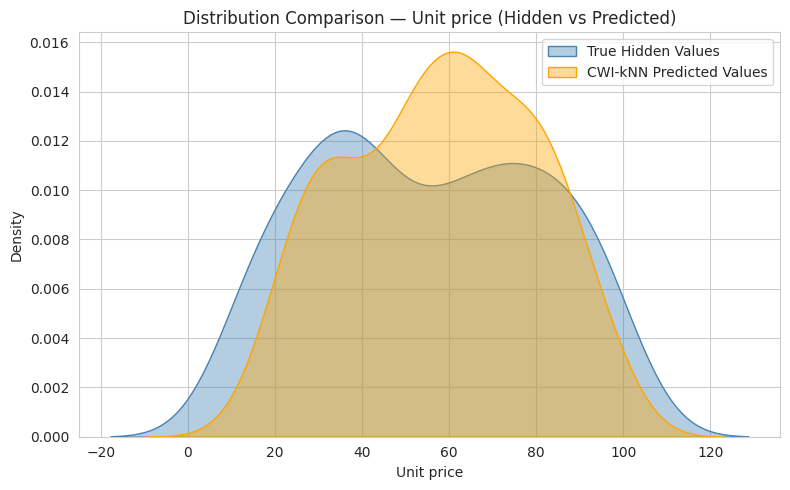

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.kdeplot(comparison_table['Original Value (hidden)'], label='True Hidden Values', fill=True, alpha=0.4, color='steelblue')
sns.kdeplot(comparison_table['CWI-kNN Predicted'], label='CWI-kNN Predicted Values', fill=True, alpha=0.4, color='orange')

plt.title(f"Distribution Comparison — {col} (Hidden vs Predicted)")
plt.xlabel(col)
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

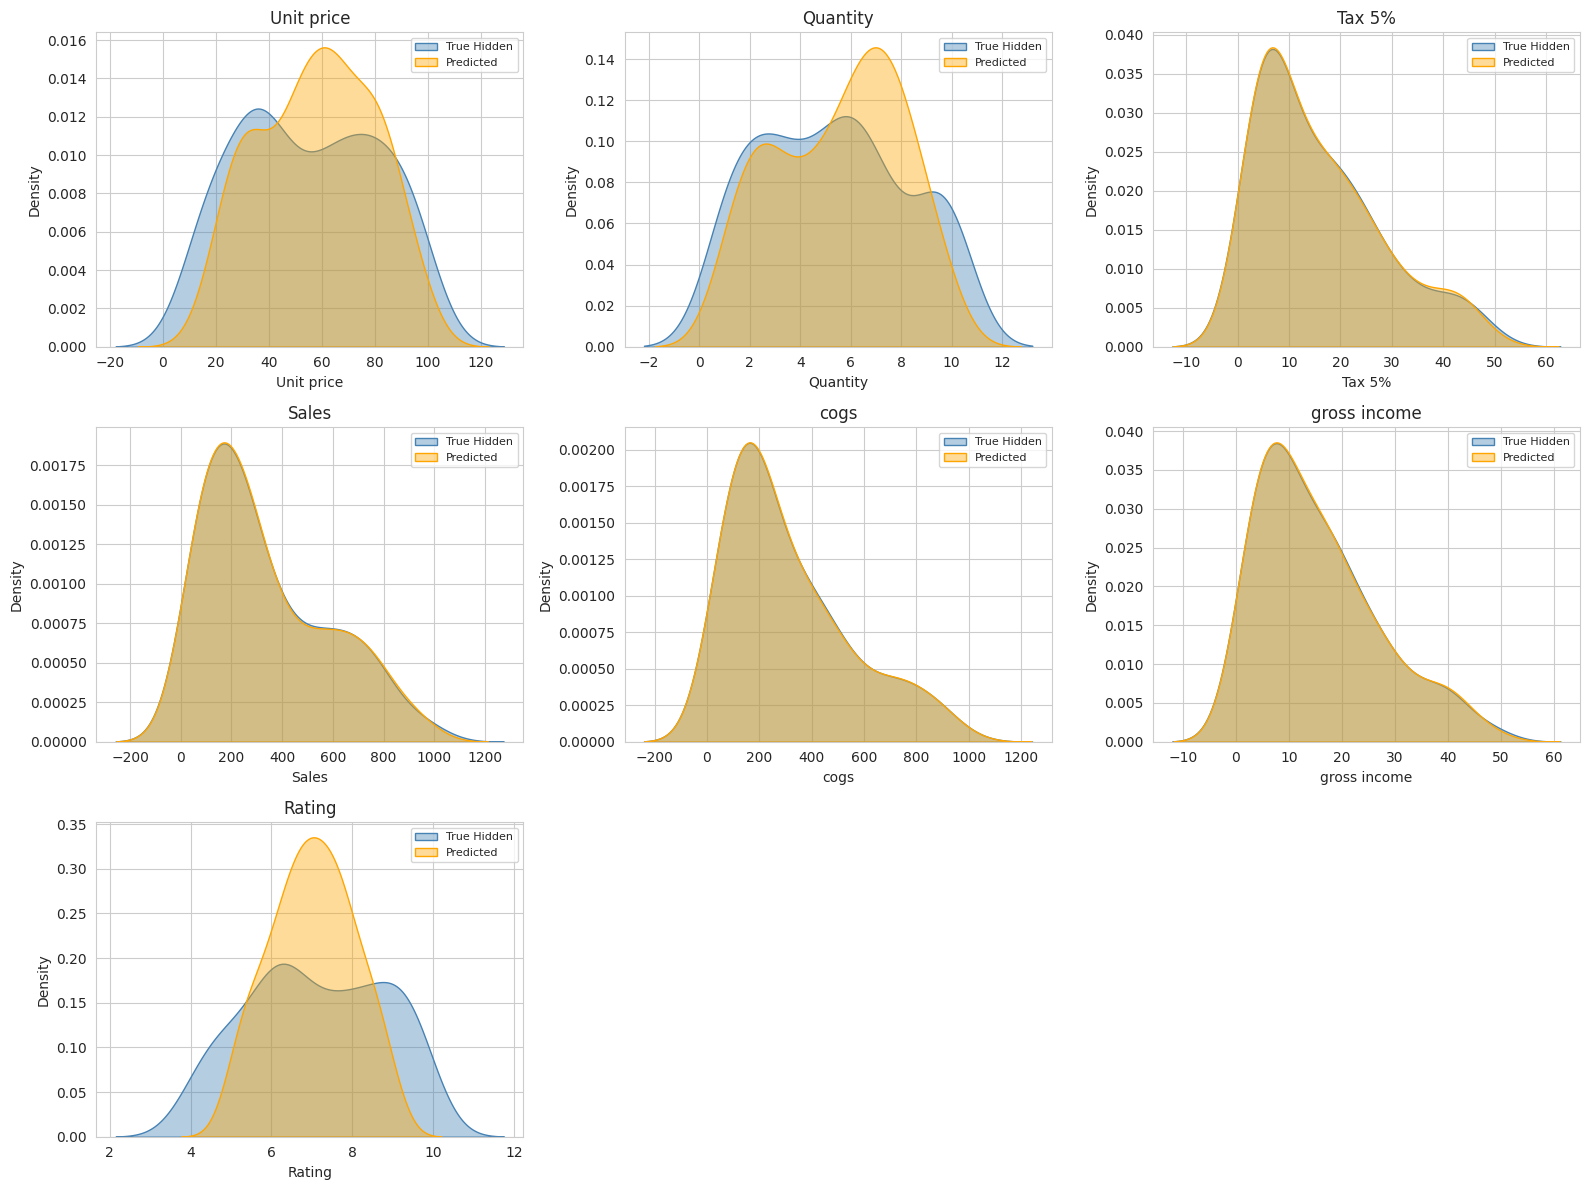

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, c in enumerate(numeric_cols):
    true_hidden = data.loc[mask_demo[c], c]
    predicted = imputed_demo.loc[mask_demo[c], c]

    sns.kdeplot(true_hidden, label='True Hidden', fill=True, alpha=0.4, color='steelblue', ax=axes[i])
    sns.kdeplot(predicted, label='Predicted', fill=True, alpha=0.4, color='orange', ax=axes[i])
    axes[i].set_title(c)
    axes[i].legend(fontsize=8)

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Step 5 — The baseline methods

To make a fair comparison, we implement the three standard imputation methods: Mean (fills with the column average), Median (fills with the column middle value), and KNN (scikit-learn's built-in K-Nearest-Neighbors imputer, which uses all columns equally).

In [ ]:
def mean_impute(data_missing, columns):
    out = data_missing.copy()
    out[columns] = out[columns].fillna(out[columns].mean())
    return out[columns]

def median_impute(data_missing, columns):
    out = data_missing.copy()
    out[columns] = out[columns].fillna(out[columns].median())
    return out[columns]

def sklearn_knn_impute(data_missing, columns, k=5):
    imputer = KNNImputer(n_neighbors=k)
    arr = imputer.fit_transform(data_missing[columns])
    return pd.DataFrame(arr, columns=columns, index=data_missing.index)

print("Baseline methods ready: Mean, Median, KNN (scikit-learn).")

Baseline methods ready: Mean, Median, KNN (scikit-learn).


## Step 6 — Evaluation metric

We use **RMSE (Root Mean Squared Error)** and **MAE (Mean Absolute Error)**, computed **only on the cells we artificially removed** (since those are the only ones where we know the true answer). Lower is better for both.

In [ ]:
def evaluate(true_data, imputed_data, mask, columns):
    all_true, all_pred = [], []
    for col in columns:
        m = mask[col]
        if m.sum() == 0:
            continue
        all_true.extend(true_data.loc[m, col].values)
        all_pred.extend(imputed_data.loc[m, col].values)
    rmse = np.sqrt(mean_squared_error(all_true, all_pred))
    mae = mean_absolute_error(all_true, all_pred)
    return rmse, mae

print("Evaluation function ready.")

Evaluation function ready.


## Step 7 — Run the full comparison

We repeat the experiment at several missing-value rates (5%, 10%, 20%, 30%) so we can see how each method holds up as more data goes missing — not just a single lucky/unlucky case.

In [ ]:
missing_rates = [0.05, 0.10, 0.20, 0.30]
results = []

for rate in missing_rates:
    dm, mask = introduce_missing(data, numeric_cols, rate, seed=1)

    methods = {
        'Mean':                 mean_impute(dm, numeric_cols),
        'Median':               median_impute(dm, numeric_cols),
        'KNN (sklearn)':        sklearn_knn_impute(dm, numeric_cols, k=5),
        'Our Method (CWI-kNN)': cwi_knn_impute(dm, numeric_cols, k=5, top_m=3, n_iterations=2),
    }

    for name, imputed in methods.items():
        rmse, mae = evaluate(data, imputed, mask, numeric_cols)
        results.append({'Missing Rate': f"{int(rate*100)}%", 'Method': name, 'RMSE': rmse, 'MAE': mae})

results_df = pd.DataFrame(results)
results_df

,Missing Rate,Method,RMSE,MAE
0,5%,Mean,135.307127,63.063189
1,5%,Median,146.757316,64.609441
2,5%,KNN (sklearn),9.544633,4.960272
3,5%,Our Method (CWI-kNN),9.311856,3.162358
4,10%,Mean,119.707687,57.019606
5,10%,Median,125.754676,56.913289
6,10%,KNN (sklearn),15.884331,6.133856
7,10%,Our Method (CWI-kNN),7.451331,2.661519
8,20%,Mean,130.445358,64.479098
9,20%,Median,136.629684,63.542452


## Step 8 — Results as tables

In [ ]:
print("RMSE (lower = better)")
display(results_df.pivot(index='Missing Rate', columns='Method', values='RMSE').round(2))

print("\nMAE (lower = better)")
display(results_df.pivot(index='Missing Rate', columns='Method', values='MAE').round(2))

RMSE (lower = better)


Method,KNN (sklearn),Mean,Median,Our Method (CWI-kNN)
Missing Rate,,,,
10%,15.88,119.71,125.75,7.45
20%,43.87,130.45,136.63,25.79
30%,83.19,127.92,134.14,19.57
5%,9.54,135.31,146.76,9.31



MAE (lower = better)


Method,KNN (sklearn),Mean,Median,Our Method (CWI-kNN)
Missing Rate,,,,
10%,6.13,57.02,56.91,2.66
20%,17.13,64.48,63.54,4.78
30%,33.38,61.89,60.81,4.60
5%,4.96,63.06,64.61,3.16


## Step 9 — Results as charts

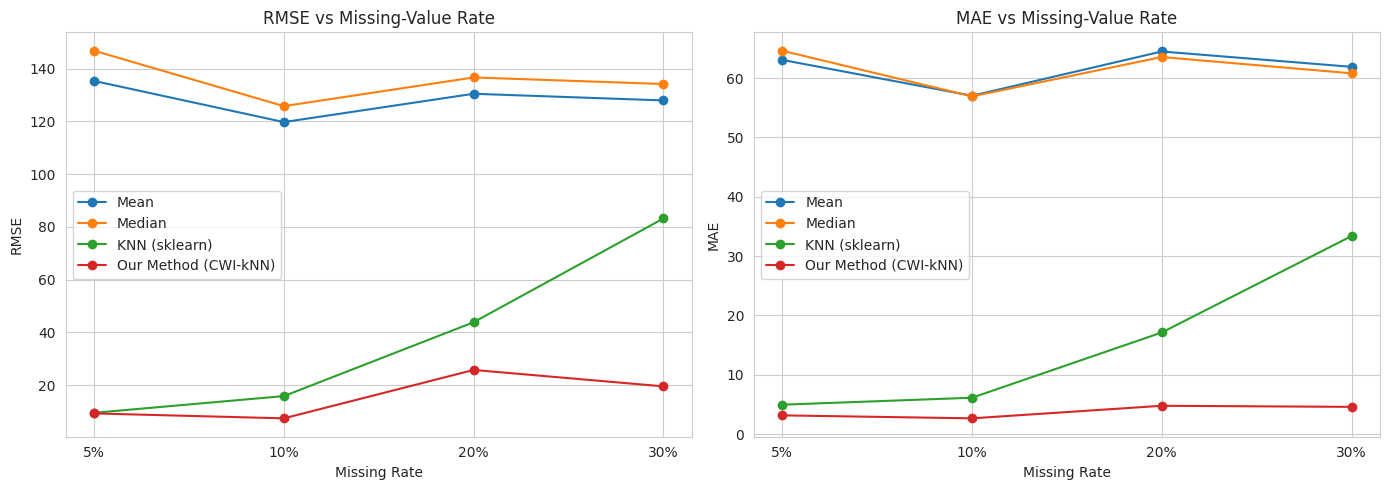

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for metric, ax in zip(['RMSE', 'MAE'], axes):
    for method in results_df['Method'].unique():
        subset = results_df[results_df['Method'] == method]
        ax.plot(subset['Missing Rate'], subset[metric], marker='o', label=method)
    ax.set_title(f"{metric} vs Missing-Value Rate")
    ax.set_xlabel("Missing Rate")
    ax.set_ylabel(metric)
    ax.legend()

plt.tight_layout()
plt.show()

Average performance across all missing rates (lower = better):


,RMSE,MAE
Method,,
Our Method (CWI-kNN),15.53,3.80
KNN (sklearn),38.12,15.40
Mean,128.34,61.61
Median,135.82,61.47


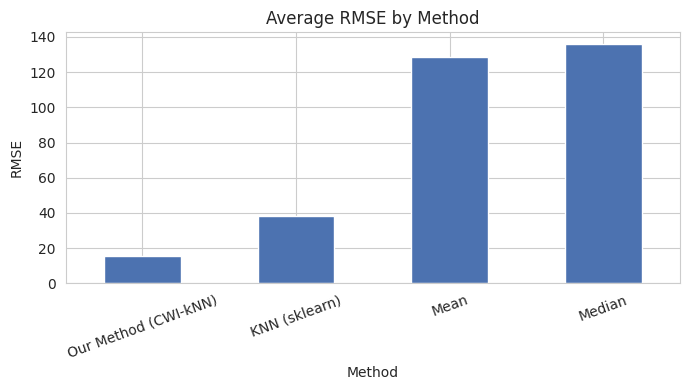

In [ ]:
avg_scores = results_df.groupby('Method')[['RMSE', 'MAE']].mean().sort_values('RMSE')
print("Average performance across all missing rates (lower = better):")
display(avg_scores.round(2))

avg_scores['RMSE'].plot(kind='bar', figsize=(7,4), title='Average RMSE by Method', color='#4C72B0')
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Step 10 — Conclusion

We summarize what the results show: Mean/Median are simplest but least accurate because they ignore relationships between columns; standard KNN improves on this by considering row similarity, but treats all columns equally; our method improves further by focusing only on the most relevant, correlated columns and refining its guesses over multiple passes. Because it relies only on correlation and distance — not on anything specific to this dataset — it will generalize to any dataset, which is the foundation for the user-friendly imputation app we plan to build next.
